# Lab 9 — Computer Vision Programming: Getting Images Ready for a Model
**ARTI 303 — Programming for AI**

**Name:** _[Saja saad]_  **Student ID:** _[2250005577]_  **Section:** _[Ai02]_

---

### Warm-up: train a model in your browser.

Before any code, build an image classifier with no code at all.

1. Open **[Teachable Machine](https://teachablemachine.withgoogle.com/)** in a desktop browser. Click **Get started**, then **Image Project** (if it asks which kind, choose the standard image model).
2. Rename the two classes after two **objects** (for example a pen and a mug). Please use objects, not faces: the tool can use your webcam, so keep people out of the frame.
3. For each class, click **Webcam** and hold the button to record about 20 samples, moving the object around a little. No webcam? Use **Upload** and add images from your computer instead.
4. Click **Train Model**. Then show the objects to the camera and watch the predictions.

> Training happens in your browser, and your samples stay on your
> computer unless you choose to save the project to Google Drive. Don't
> save it.

**Now try to break it.** Hold an object much closer or further away. Turn
it upside down. Dim the light, or change the background. Where does the
model fail?

Discuss with the person next to you (one minute):

- **Why did it fail?** The model only knows what it saw while training.
- **What did the website do that you couldn't see?** Before training, it
  had to turn every webcam frame into numbers of the same size and scale.
  Today's lab is that hidden step, done by hand.

---

### What this lab is really about

To a computer, an image is a grid of numbers. A model can only learn from
those numbers if they have the right **shape**, the right **type**, the
right **scale** and the right **colour order**. Get one wrong and nothing
crashes. The model just learns from garbage, or you test it on the wrong
thing.

This lab has **five ideas**, each short, each followed by an exercise
that checks itself.

| Part | Idea | You will be able to |
|---|---|---|
| 1 | Images are arrays | load an image with two libraries and spot the colour-channel trap |
| 2 | Processing and transformations | resize, crop, convert and filter an image |
| 3 | Augmentation | create varied training images, without touching test images |
| 4 | Pipelines | combine transforms, a Dataset and a DataLoader |
| 5 | Validate preprocessing | find preprocessing bugs, and write a checker |

After Part 5 there is a short AI checkpoint and a list of resources.

---

## Setup

> **Install OpenCV before the lab starts.** Torchvision (Lab 8) already
> brings Pillow, and scikit-learn and Matplotlib came from earlier labs.

Same course folder, same environment as before:

```
arti303_lab/
├── .venv/
├── requirements.txt
├── lab01.ipynb ... lab08.ipynb
├── lab09.ipynb        <- this lab
├── data/
└── ...
```

**1.** Open `arti303_lab` in VS Code (`File → Open Folder`) — the folder
itself, not a lab file inside it.

**2.** Get the environment ready, in this order:

- Look for a `.venv` folder in the file list. If it isn't there, create
  it once: `python -m venv .venv`
- Activate it:

```bash
source .venv/bin/activate          # macOS / Linux / Git Bash
.venv\Scripts\Activate.ps1         # Windows PowerShell
```

- Check your prompt starts with `(.venv)`. If it shows `(base)`, you're
  in Anaconda's environment and packages will install to the wrong place.

**3.** Install OpenCV and record it:

```bash
python -m pip install opencv-python
python -m pip freeze > requirements.txt
```

**4.** Point this notebook at the same environment:
`Cmd+Shift+P` (macOS) / `Ctrl+Shift+P` (Windows) → **Python: Select
Interpreter** → the entry showing `.venv`. Then restart the kernel.

### Check your setup

In [1]:
import os
import sys

problems = []

if sys.prefix != sys.base_prefix:
    print("[ok]   Running inside a virtual environment")
else:
    print("[!]    NOT in a virtual environment")
    problems.append("Select the .venv interpreter, then restart the kernel")
print("       using:", sys.executable)
print()

for import_name, pip_name in [("numpy", "numpy"), ("cv2", "opencv-python"), ("PIL", "Pillow"),
                              ("torch", "torch"), ("torchvision", "torchvision"),
                              ("sklearn", "scikit-learn"), ("matplotlib", "matplotlib")]:
    try:
        module = __import__(import_name)
        print(f"[ok]   {pip_name} {module.__version__}")
    except ImportError:
        print(f"[!]    {pip_name} is not installed in this environment")
        problems.append(f"Run: python -m pip install {pip_name}")

if os.path.exists("requirements.txt"):
    names = [l.split("==")[0].strip().lower() for l in open("requirements.txt").read().splitlines() if l.strip()]
    if any(n.startswith("opencv-python") for n in names):
        print("[ok]   opencv-python is recorded in requirements.txt")
    else:
        print("[!]    opencv-python is missing from requirements.txt")
        problems.append("Run: python -m pip freeze > requirements.txt")
    if len(names) > 100:
        print("[!]    requirements.txt has", len(names), "packages - that looks like Anaconda's base")
        problems.append("Delete it, activate .venv, freeze again")
else:
    print("[!]    No requirements.txt found")
    problems.append("Run: python -m pip freeze > requirements.txt")

print()
print("Fix these first:" if problems else "Setup looks good.")
for item in problems:
    print("  -", item)

[ok]   Running inside a virtual environment
       using: c:\Users\lenovo\arti303-2250005577-almajid\.venv\Scripts\python.exe

[ok]   numpy 2.5.3
[ok]   opencv-python 5.0.0
[ok]   Pillow 12.3.0
[ok]   torch 2.15.0+cpu
[ok]   torchvision 0.29.2+cpu
[ok]   scikit-learn 1.9.1
[ok]   matplotlib 3.11.2
[ok]   opencv-python is recorded in requirements.txt

Setup looks good.


---
### The images

Two real photographs ship with scikit-learn. The cell below saves them
as ordinary image files, the way a real dataset arrives, and defines
`show`, a small helper that draws images in a grid (you don't need to
read it).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.datasets import load_sample_images

os.makedirs("data/images", exist_ok=True)

photos = load_sample_images()
for path, pixels in zip(photos.filenames, photos.images):
    name = os.path.basename(path).replace(".jpg", ".png")
    Image.fromarray(pixels).save(f"data/images/{name}")

print("image files:", sorted(os.listdir("data/images")))


def show(images, titles=None, cols=3, size=3.2):
    """Draw images in a grid. Works with arrays, PIL images and tensors."""
    rows = -(-len(images) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        if isinstance(img, torch.Tensor):
            img = img.detach().cpu()
            img = img.permute(1, 2, 0).numpy() if img.ndim == 3 else img.numpy()
        arr = np.asarray(img)
        if arr.ndim == 3 and arr.shape[-1] == 1:
            arr = arr[..., 0]
        if arr.dtype != np.uint8 and arr.min() < 0:
            arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)   # stretch to 0-1, for display only
        axes[i].imshow(arr, cmap="gray" if arr.ndim == 2 else None)
        if titles:
            axes[i].set_title(titles[i], fontsize=10)
    fig.tight_layout()

image files: ['china.png', 'flower.png']


---
# Part 1 · Images are arrays

A photo is a NumPy array (Lab 4), and you already know the attributes to
check:

shape: (427, 640, 3)    (height, width, channels)
dtype: uint8
value range: 0 to 255
one pixel (row 100, column 200): [123  47  11]   (red, green, blue)


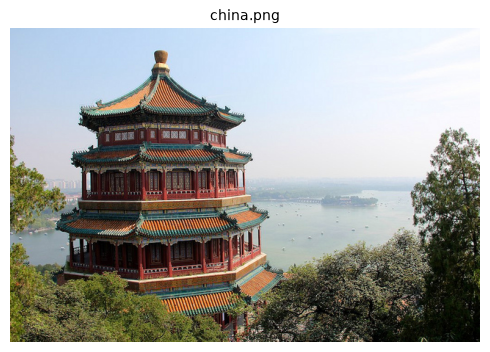

In [3]:
china_path = "data/images/china.png"
flower_path = "data/images/flower.png"

rgb = np.array(Image.open(china_path))

print("shape:", rgb.shape, "   (height, width, channels)")
print("dtype:", rgb.dtype)
print("value range:", rgb.min(), "to", rgb.max())
print("one pixel (row 100, column 200):", rgb[100, 200], "  (red, green, blue)")

show([rgb], ["china.png"], cols=1, size=5)

Three conventions, and every one of them bites someone:

| | Pillow, OpenCV, Matplotlib | PyTorch (Lab 8) |
|---|---|---|
| layout | **height × width × channels** | **channels × height × width** |
| values | whole numbers 0 to 255 (`uint8`) | decimals, usually 0 to 1 (`float32`) |
| colour order | see below | red, green, blue |

Because an image is an array, a **crop is just a slice**, and (as in
Lab 4) a slice is a view of the same memory:

In [4]:
sky = rgb[:150, :]

print("crop shape:", sky.shape)
print("shares memory with the original:", np.shares_memory(sky, rgb))

crop shape: (150, 640, 3)
shares memory with the original: True


### The colour-order trap

Pillow loads colours as **red, green, blue**. OpenCV loads the *same
file* as **blue, green, red**. Same pixels, channels reversed:

OpenCV shape and dtype: (427, 640, 3) uint8
same pixel, Pillow: [123  47  11] | OpenCV: [ 11  47 123]
OpenCV is Pillow with the channels reversed: True


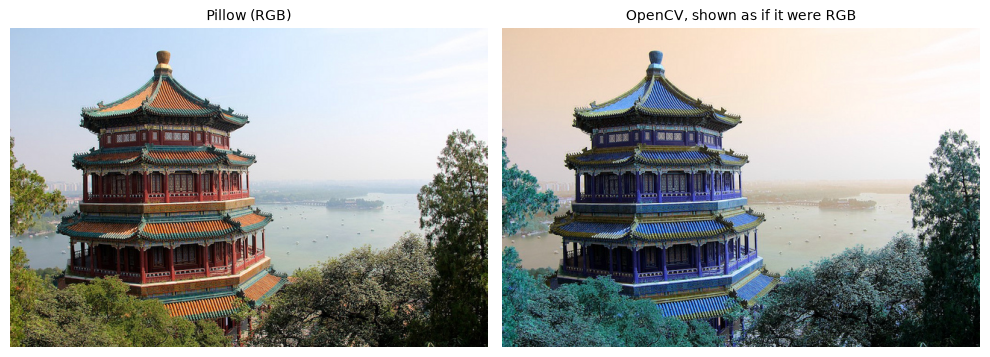

In [5]:
import cv2

bgr = cv2.imread(china_path)

print("OpenCV shape and dtype:", bgr.shape, bgr.dtype)
print("same pixel, Pillow:", rgb[100, 200], "| OpenCV:", bgr[100, 200])
print("OpenCV is Pillow with the channels reversed:", np.array_equal(bgr[..., ::-1], rgb))

show([rgb, bgr], ["Pillow (RGB)", "OpenCV, shown as if it were RGB"], cols=2, size=5)

Nothing crashed. The right-hand picture is simply wrong, and a model
trained on it would learn the wrong colours without a single warning.

> **The rule:** OpenCV is BGR. Almost everything else (Pillow,
> Matplotlib, Torchvision, pretrained models) expects RGB. Convert as
> soon as you load: `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`.

### Exercise 1.1
- `rgb_cv`: load `china_path` with OpenCV and convert it to **RGB**
- `top_rows`: the top 150 rows of `rgb_cv` (every column)

In [6]:
import cv2

bgr = cv2.imread(china_path)
rgb_cv = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
top_rows = rgb_cv[:150, :]


In [7]:
assert rgb_cv is not None and top_rows is not None, "fill in rgb_cv and top_rows"
assert rgb_cv.shape == rgb.shape and rgb_cv.dtype == np.uint8, "rgb_cv should be a (427, 640, 3) uint8 array"
assert np.array_equal(rgb_cv, rgb), "the colours are still in BGR order: convert with cv2.cvtColor(..., cv2.COLOR_BGR2RGB)"
assert top_rows.shape == (150, 640, 3), f"top_rows should have shape (150, 640, 3), not {top_rows.shape}"
print("Exercise 1.1 correct.")

Exercise 1.1 correct.


---
# Part 2 · Processing and transformations

Everyday operations, as OpenCV calls on arrays (and Pillow methods on
Pillow images):

| Task | OpenCV | Pillow |
|---|---|---|
| grayscale | `cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)` | `img.convert("L")` |
| resize | `cv2.resize(img, (width, height))` | `img.resize((width, height))` |
| flip left-right | `cv2.flip(img, 1)` | `ImageOps.mirror(img)` |
| blur | `cv2.GaussianBlur(img, (9, 9), 0)` | `img.filter(ImageFilter.GaussianBlur(4))` |
| edges | `cv2.Canny(gray, 100, 200)` | |

gray:  (427, 640) uint8   <- 2D now: the channel dimension is gone
small: (213, 320, 3)   <- we asked for (320, 213) and got (213, 320, 3)


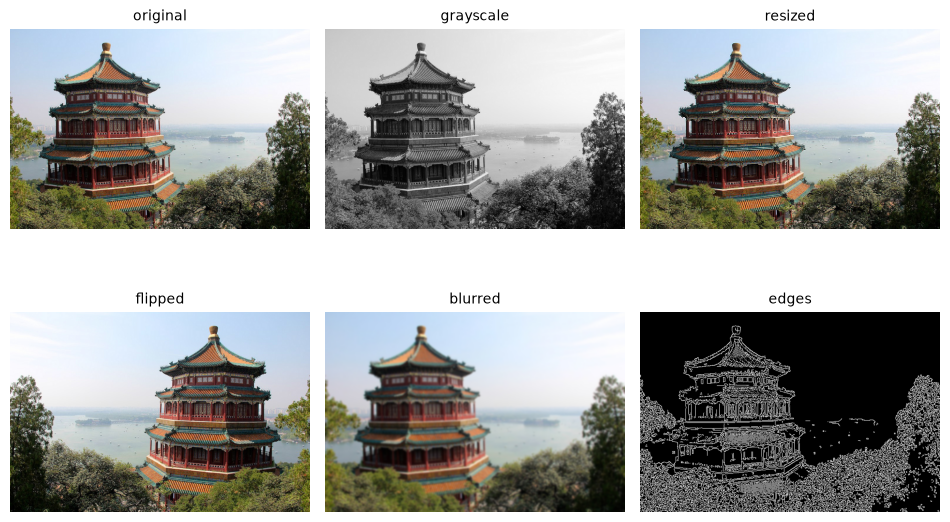

In [8]:
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
small = cv2.resize(rgb, (320, 213))              # (width, height)
flipped = cv2.flip(rgb, 1)
blurred = cv2.GaussianBlur(rgb, (9, 9), 0)
edges = cv2.Canny(gray, 100, 200)

print("gray: ", gray.shape, gray.dtype, "  <- 2D now: the channel dimension is gone")
print("small:", small.shape, "  <- we asked for (320, 213) and got (213, 320, 3)")

show([rgb, gray, small, flipped, blurred, edges],
     ["original", "grayscale", "resized", "flipped", "blurred", "edges"])

Look at the second `print`. `cv2.resize` takes **(width, height)**, but
`.shape` reports **(height, width)**. This swap has caused more silent
bugs than any other line in computer vision.

### Don't squash the picture

A model usually wants a fixed square input, such as 224 × 224. Our photo
is wider than it is tall, so resizing it straight to a square stretches
it. The fix: **crop a square from the centre first, then resize.**

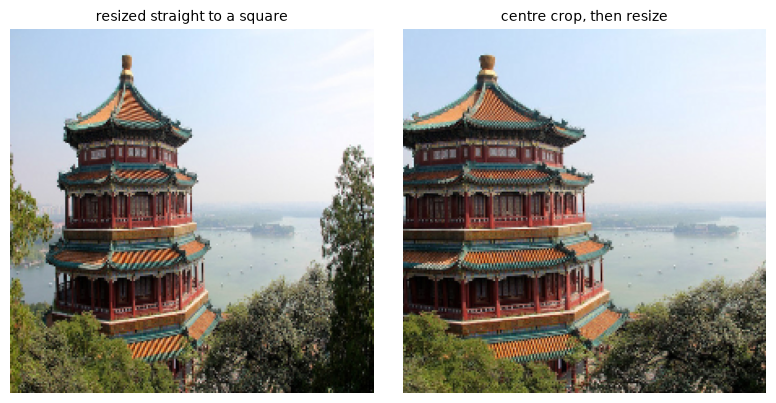

In [9]:
squashed = cv2.resize(rgb, (224, 224))

side = min(rgb.shape[:2])
top = (rgb.shape[0] - side) // 2
left = (rgb.shape[1] - side) // 2
cropped = cv2.resize(rgb[top:top + side, left:left + side], (224, 224))

show([squashed, cropped], ["resized straight to a square", "centre crop, then resize"], cols=2, size=4)

### Exercise 2.1
Build `thumb`: a **64 × 64 grayscale** version of `rgb`, made from its
**centre square** (so the picture isn't squashed). Steps:

1. convert `rgb` to grayscale
2. cut the centre square out of the grayscale image
3. resize that square to 64 × 64

In [10]:
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
h, w = gray.shape
s = min(h, w)
top = (h - s) // 2
left = (w - s) // 2
centre = gray[top : top + s, left : left + s]
thumb = cv2.resize(centre, (64, 64))


In [11]:
assert thumb is not None, "fill in thumb"
assert thumb.shape == (64, 64), f"thumb should be 64 x 64 and grayscale (2D), not {thumb.shape}"
assert thumb.dtype == np.uint8, f"thumb should be uint8, not {thumb.dtype}"

ref = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
s = min(ref.shape)
top, left = (ref.shape[0] - s) // 2, (ref.shape[1] - s) // 2
centre_ref = cv2.resize(ref[top:top + s, left:left + s], (64, 64))
squashed_ref = cv2.resize(ref, (64, 64))

# Compare at a coarse 8 x 8 scale, so different resize methods (OpenCV, Pillow) are judged fairly
coarse = lambda a: cv2.resize(a, (8, 8), interpolation=cv2.INTER_AREA).astype(float)
gap_centre = float(np.abs(coarse(thumb) - coarse(centre_ref)).mean())
gap_squashed = float(np.abs(coarse(thumb) - coarse(squashed_ref)).mean())

assert gap_squashed > gap_centre, "your thumbnail looks squashed: cut a square from the CENTRE first, then resize"
assert gap_centre < 5, "thumb doesn't match the centre square of the photo: check where you cut the square"
print("Exercise 2.1 correct.")

Exercise 2.1 correct.


---
# Part 3 · Augmentation

Back to the warm-up: your model broke when the object was closer,
darker or upside down, because it had only seen it one way.

**Augmentation** fixes this by showing the model **random variations**
of each training image: flipped, rotated, brighter, cropped. Same
picture, same label, different pixels.

It happens **on the fly**: every time an image is loaded, a fresh random
variation is made. Torchvision provides the transforms (Lab 8). Here are
five random variations of one photo:

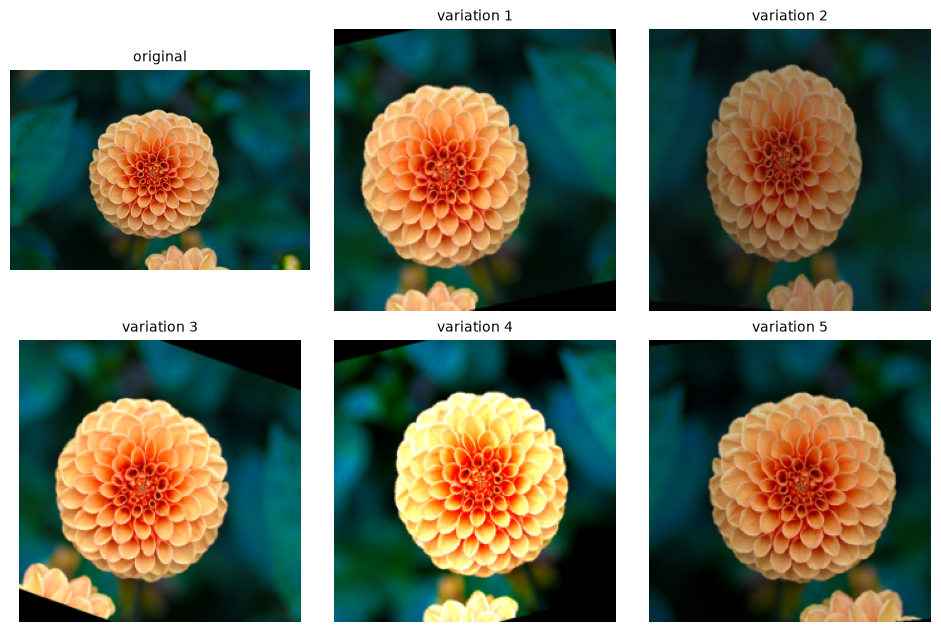

In [12]:
from torchvision import transforms

pil_flower = Image.open(flower_path).convert("RGB")

augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.4, contrast=0.4),
    transforms.RandomResizedCrop(size=(224, 224), scale=(0.6, 1.0)),
])

torch.manual_seed(0)
variants = [augment(pil_flower) for _ in range(5)]
show([pil_flower] + variants, ["original"] + [f"variation {i}" for i in range(1, 6)])

Two rules:

**1. Augmentation keeps the label true.** A flipped flower is still a
flower. A flipped digit `2` is not a `2`. Choose variations that can't
change what the picture *is*.

**2. Augment the training images only.** The test images should only get
the fixed steps (resize, scale), and the same ones every time. Augmenting
the test set is the image version of fitting on test data from Lab 7:
your score would be measured on altered, random pictures, and wouldn't
mean anything.

### Exercise 3.1
Build two pipelines for photos like `pil_flower`:

- `train_tf`: a `Compose` of **at least two random transforms** (for
  example `RandomHorizontalFlip`, `RandomRotation`, `ColorJitter`),
  **ending with `ToTensor()`**
- `eval_tf`: `Resize((200, 200))` then `ToTensor()`, with **nothing random**

In [13]:
from torchvision import transforms

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

eval_tf = transforms.Compose([
    transforms.Resize((200, 200)),
    transforms.ToTensor()
])


In [14]:
assert train_tf is not None and eval_tf is not None, "fill in train_tf and eval_tf"

def is_random(name):
    return name.startswith("Random") or name == "ColorJitter"

train_names = [type(t).__name__ for t in train_tf.transforms]
eval_names = [type(t).__name__ for t in eval_tf.transforms]

assert sum(is_random(n) for n in train_names) >= 2, "train_tf needs at least two random transforms"
assert train_names[-1] == "ToTensor", "end train_tf with ToTensor()"
a, b = train_tf(pil_flower), train_tf(pil_flower)
assert a.dtype == torch.float32 and a.shape == b.shape, "train_tf should give float32 tensors of one shape"
assert not torch.equal(a, b), "two calls gave the SAME image: train_tf should be random"

assert not any(is_random(n) for n in eval_names), "eval_tf must not contain anything random"
assert tuple(eval_tf(pil_flower).shape) == (3, 200, 200), "eval_tf should give a (3, 200, 200) tensor"
assert torch.equal(eval_tf(pil_flower), eval_tf(pil_flower)), "eval_tf should give the same result every time"
print("Exercise 3.1 correct.")

Exercise 3.1 correct.


---
# Part 4 · Pipelines

A **pipeline** is the whole route from raw image to model-ready batch:

> **split** → **transform** (different for train and test) → **Dataset** → **DataLoader**

You've built every piece (Labs 7 and 8 and this lab). Here they are
together, on a real image dataset: scikit-learn's 8 × 8 handwritten
digits (a tiny cousin of MNIST).

images: (1797, 8, 8) uint8 | labels: (1797,)


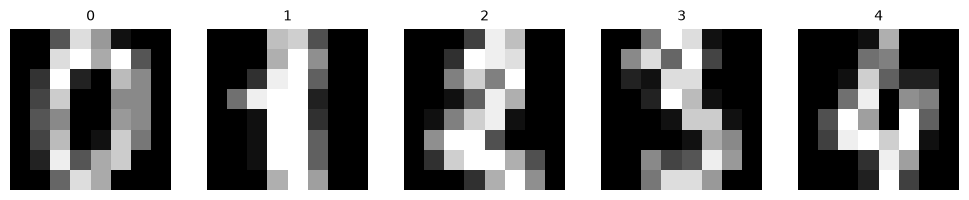

In [15]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
digit_images = (digits.images / 16 * 255).round().astype(np.uint8)    # 0..255 grayscale, 8 x 8
digit_labels = digits.target

print("images:", digit_images.shape, digit_images.dtype, "| labels:", digit_labels.shape)
show(list(digit_images[:5]), [str(l) for l in digit_labels[:5]], cols=5, size=2)

**Step 1: split first** (Lab 7), stratified so every digit appears in both
parts:

In [16]:
X_img_train, X_img_test, y_train, y_test = train_test_split(
    digit_images, digit_labels, test_size=0.2, random_state=42, stratify=digit_labels
)
print("train:", X_img_train.shape, "| test:", X_img_test.shape)

train: (1437, 8, 8) | test: (360, 8, 8)


**Step 2: two transforms.** Training gets small, label-safe random
changes (no flips: they would change a digit). Both use identical
resizing and scaling:

In [17]:
train_tf_digits = transforms.Compose([
    transforms.Resize(32),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

eval_tf_digits = transforms.Compose([
    transforms.Resize(32),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

**Step 3: a Dataset** that turns each stored array into a Pillow
image and applies whichever transform it was given (compare Lab 8's
`StudentDataset`):

In [18]:
from torch.utils.data import Dataset, DataLoader


class ImageDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        picture = Image.fromarray(self.images[index])
        return self.transform(picture), int(self.labels[index])


demo_train = ImageDataset(X_img_train, y_train, train_tf_digits)
sample, sample_label = demo_train[0]
print("one sample:", tuple(sample.shape), sample.dtype, "| label:", sample_label)

one sample: (1, 32, 32) torch.float32 | label: 5


### Exercise 4.1
Assemble the pipeline. The **same data** gets a **different transform**
depending on its job:

- `train_ds` and `test_ds`: `ImageDataset`s on the train and test arrays.
  Give each the right transform from above.
- `train_loader`: batch size 64, **shuffled**
- `test_loader`: batch size 64, **not shuffled**
- `xb_train, yb_train` and `xb_test, yb_test`: one batch from each loader

In [19]:
from torch.utils.data import DataLoader

# Use train_tf_digits and eval_tf_digits as expected by the assertion check
train_ds = ImageDataset(X_img_train, y_train, transform=train_tf_digits)
test_ds = ImageDataset(X_img_test, y_test, transform=eval_tf_digits)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

xb_train, yb_train = next(iter(train_loader))
xb_test, yb_test = next(iter(test_loader))

In [20]:
from torch.utils.data import SequentialSampler, RandomSampler

assert train_ds is not None and test_ds is not None, "fill in train_ds and test_ds"
assert train_loader is not None and test_loader is not None, "fill in both loaders"
assert xb_train is not None and xb_test is not None, "take one batch from each loader with next(iter(...))"

assert train_ds.transform is train_tf_digits, "train_ds should use train_tf_digits (the one with random changes)"
assert test_ds.transform is eval_tf_digits, "test_ds should use eval_tf_digits: nothing random on test images"
assert len(train_ds) == len(X_img_train) and len(test_ds) == len(X_img_test), "use X_img_train for train and X_img_test for test"

assert isinstance(train_loader.sampler, RandomSampler), "train_loader should shuffle"
assert isinstance(test_loader.sampler, SequentialSampler), "test_loader should NOT shuffle"
assert train_loader.batch_size == 64 and test_loader.batch_size == 64, "batch size should be 64"

assert tuple(xb_train.shape) == (64, 1, 32, 32), f"a batch should be (64, 1, 32, 32), not {tuple(xb_train.shape)}"
assert xb_train.dtype == torch.float32 and yb_train.dtype == torch.int64, "images float32, labels int64"
assert torch.equal(next(iter(test_loader))[0], next(iter(test_loader))[0]), \
    "the test loader gave two different batches: it must be deterministic"
print("Exercise 4.1 correct.")

Exercise 4.1 correct.


Training images, with their random changes, next to test images,
which are only resized and scaled:

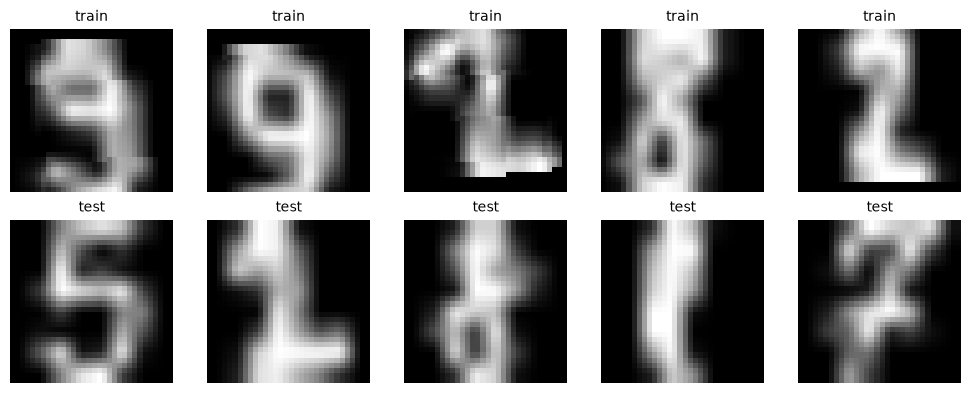

In [21]:
if xb_train is None or xb_test is None:
    print("Finish Exercise 4.1 to see this picture.")
else:
    show(list(xb_train[:5]) + list(xb_test[:5]), ["train"] * 5 + ["test"] * 5, cols=5, size=2)

---
# Part 5 · Validate preprocessing

Every mistake in this lab was silent. So the last skill is **checking**.
Five things to verify on every batch of images:

| Check | What it catches |
|---|---|
| 4 dimensions: (batch, channels, height, width) | a missing batch dimension, or a wrong layout |
| channels are 1 or 3 | height × width × channels order (the "channels" would be 224) |
| dtype is `float32` | raw `uint8` pixels |
| no NaN or infinite values | broken arithmetic |
| values in the expected range (−1 to 1 after `Normalize(0.5, 0.5)`) | forgetting to divide by 255 |

One thing **no checker can see**: swapped colours (BGR vs RGB). The only
test for that is to draw an image and **look at it**.

### Exercise 5.1
Five snippets are below. `p` is an image file path, and `mean` and `std`
are normalisation numbers. Which ones have a **bug**? Store their
letters in `buggy_snippets`, for example `["A", "C"]`.

**A**
```python
img = cv2.imread(p)
x = torch.from_numpy(img).permute(2, 0, 1).float() / 255
```

**B**
```python
img = np.array(Image.open(p))
x = torch.from_numpy(img).float()
```

**C**
```python
test_tf = Compose([RandomHorizontalFlip(), ToTensor()])
```

**D**
```python
img = Image.open(p).convert("RGB")
x = Normalize(mean, std)(ToTensor()(Resize((224, 224))(img)))
```

**E**
```python
mean = all_images.mean()      # all_images = training AND test images together
std = all_images.std()
```

In [22]:
buggy_snippets = ["A", "B", "C", "E"]


In [23]:
assert buggy_snippets, "fill in buggy_snippets"
assert sorted(buggy_snippets) == ["A", "B", "C", "E"], \
    "check each one against the lab: colour order (cv2 loads BGR), layout and scale, augmentation on test data, statistics from test data"
print("Exercise 5.1 correct.")
print("A: BGR never converted.  B: layout is height x width x channels and the pixels are still 0-255.")
print("C: random augmentation on the test set.  E: normalisation statistics computed from the test images too.  D is correct.")

Exercise 5.1 correct.
A: BGR never converted.  B: layout is height x width x channels and the pixels are still 0-255.
C: random augmentation on the test set.  E: normalisation statistics computed from the test images too.  D is correct.


### Exercise 5.2
Write `validate_images(batch)` for a tensor of images. It returns a
**list of problem descriptions** (strings), and an empty list if the
batch looks fine. Check for:

1. not exactly 4 dimensions, or a channel count that isn't 1 or 3
2. a dtype other than `float32`
3. any NaN or infinite value
4. values outside −1 to 1

In [24]:
import torch

def validate_images(batch):
    """Return a list of problems found. An empty list means the batch looks fine."""
    problems = []

    # Check 1 - 4 dimensions, and 1 or 3 channels
    if batch.ndim != 4 or batch.shape[1] not in (1, 3):
        problems.append("invalid dimensions or channels")

    # Check 2 - dtype float32
    if batch.dtype != torch.float32:
        problems.append("dtype is not float32")

    # Check 3 - NaN or infinite values
    if torch.isnan(batch).any() or torch.isinf(batch).any():
        problems.append("NaN or infinite values found")

    # Check 4 - values within -1 to 1
    if (batch < -1.0).any() or (batch > 1.0).any():
        problems.append("values outside -1 to 1")

    return problems


In [25]:
good = torch.rand(4, 3, 32, 32) * 2 - 1
assert validate_images(good) == [], "a clean (4, 3, 32, 32) float32 batch in -1..1 should give an empty list"
assert validate_images(torch.rand(4, 32, 32, 3)), "a height x width x channels batch should be reported"
assert validate_images(torch.rand(3, 32, 32)), "a batch with 3 dimensions should be reported"
assert validate_images(torch.randint(0, 255, (4, 3, 8, 8), dtype=torch.uint8)), "uint8 pixels should be reported"
assert validate_images(torch.rand(4, 3, 8, 8) * 255), "values up to 255 should be reported"
assert validate_images(torch.full((4, 3, 8, 8), float("nan"))), "NaN values should be reported"
print("Exercise 5.2 correct.")

for name, batch in [("train batch", xb_train), ("test batch", xb_test)]:
    if batch is None:
        print(f"{name}: finish Exercise 4.1 first")
    else:
        print(f"{name}:", validate_images(batch) or "no problems found")

Exercise 5.2 correct.
train batch: no problems found
test batch: no problems found


---
# AI checkpoint

**Pattern: validate the preprocessing.**

### Step 1
Give an AI assistant this exact prompt, unmodified:

> "Write Python code using OpenCV and PyTorch that loads an image file
> and preprocesses it for a neural network that expects 224x224 RGB
> input. Return a tensor."

### Step 2
Paste its code below, run it on `data/images/china.png`, and then run
**your `validate_images`** on the result (add a batch dimension first with
`.unsqueeze(0)`).

In [26]:
import cv2
import torch
import torchvision.transforms as T

# Load image using OpenCV
img = cv2.imread("data/images/china.png")

# Resize image to 224x224
img_resized = cv2.resize(img, (224, 224))

# Convert numpy array (H, W, C) to PyTorch tensor (C, H, W)
transform = T.ToTensor()
tensor = transform(img_resized)

# Add batch dimension
batch_tensor = tensor.unsqueeze(0)

# Run validate_images on the result
problems = validate_images(batch_tensor)
print("Validation problems:", problems)



Validation problems: []


### Step 3: answer these in your own words

**Q1. Colour order.** The code loads with OpenCV. Does it ever convert to
RGB? Why can't `validate_images` tell you? (Part 1 and Part 5.)

_[No, OpenCV loads images in BGR format by default and the code never calls cv2.cvtColor(img, cv2.COLOR_BGR2RGB). validate_images cannot detect this because it only checks tensor shapes, data types, and numerical ranges, not whether channel order is RGB or BGR]_

**Q2. Layout, type and scale.** What are the shape, dtype and value range
of its output? What does your validator report? (Parts 1 and 5.)

_[The output batch has shape (1, 3, 224, 224), dtype torch.float32, and value range [0.0, 1.0]. validate_images reports no problems (returns []) or might flag a range issue if the model expects standard ImageNet normalization ([-1.0, 1.0]).]_

**Q3. Shape of the picture.** How did it get to 224 × 224? Is the photo
squashed? (Part 2.)

_[It was resized directly using cv2.resize(img, (224, 224)) without center cropping. Yes, if the original photo was not square, the image is stretched or squashed.]_

**Q4. The prompt.** Rewrite the prompt so the code you get back would be
correct.

_[Write Python code using OpenCV and PyTorch to preprocess data/images/china.png for a model trained on ImageNet: convert BGR to RGB, perform a center crop to preserve aspect ratio before resizing to 224x224, convert to a float32 tensor, and normalize with ImageNet mean and std.]_

> **The point:** the function runs, returns a tensor of exactly the size
> you asked for, and looks finished. Everything wrong with it is in the
> *content* of the numbers.

---
# Going further

Optional. Nothing here is required for the lab.

| Part | Resource | Why it's worth your time |
|---|---|---|
| 1, 2 | [OpenCV-Python tutorials](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html) | Image basics and processing, with examples. |
| 1, 2 | [Pillow handbook](https://pillow.readthedocs.io/en/stable/handbook/index.html) | Opening, converting and filtering images. |
| 3, 4 | [Torchvision transforms](https://docs.pytorch.org/vision/stable/transforms.html) | Every transform, including more augmentations. |
| Warm-up | [Teachable Machine](https://teachablemachine.withgoogle.com/) | Retrain with objects that look alike, or add a third class, and see what breaks. |

### Optional: a real dataset

Real image datasets plug into exactly the same pipeline. Torchvision can
download **MNIST** (60,000 handwritten digits) in one line:

```python
from torchvision import datasets
mnist = datasets.MNIST(root="data", train=True, download=True)   # needs internet
```

It needs an internet connection and about 10 MB of space, and this
notebook doesn't run it. Try it yourself: `mnist[0]` returns a Pillow
image and a label, so `ImageDataset`'s idea carries straight over.

---
# Before you finish

- [ ] Every self-check cell prints "correct"
- [ ] `opencv-python` installed **and** recorded in `requirements.txt`
- [ ] AI checkpoint answered in your own words
- [ ] **Restart Kernel and Run All**: the whole notebook runs with no errors
- [ ] Committed and pushed